<a href="https://colab.research.google.com/github/RinkaReiRiu/ask_Somatization/blob/main/TKU_413731000_ET3A_%E4%BD%99%E4%BA%AE%E6%99%A8_%E7%AC%AC%E4%B8%83%E9%80%B1%E4%BD%9C%E6%A5%AD1020.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TKU 413731000 ET3A 余亮晨 第七週作業1020

https://colab.research.google.com/drive/1ejfiJKi5h1UbZX8PjoN2_M3I5XtPzM-9?usp=sharing

## 作業說明

在這週的閃電秀過後，我認為要想了解軀體化症狀，不只是要從接觸患者，也需要模擬從第三人稱視角切入來觀察。因此，這週我決定要透過 RAG 來製作一個從第三方視角回答軀體化症狀的生成式 AI 機器人。

### 免責聲明

文章內容皆是為 RAG 教學重寫的簡短摘要。**內容僅供醫學知識科普使用；不能替代執業醫師當面診斷。請謹慎參閱。**

### 步驟說明

流程大致如下：

1.   載入索引與文件
2.   問題 embedding
3.   FAISS 精確搜尋
4.   組合說明文字
5.   AIsuite
6.   Gradio 製作介面並排版

## 實作階段

### 0. 事前準備

詳情請見前置作業 ipynb。

https://colab.research.google.com/drive/1_fZ0anoZf1OhCKA6tUptVQ8chCowiWGy?usp=sharing

簡單來說，需要先準備經過處理的向量和資料檔案。在上面的筆記本內已經完成處理，並進行壓縮下載。

另外，要準備 Groq 金鑰，放在 Colab 左邊的鑰匙符號選單內。命名為 Groq。

### 1. 載入套件

熟悉的載入套件環節。

*   `transformers`：Transformer 大人，又稱變形金剛。具備如多腦運算般的邏輯。
*   `sentence-transformers`：將文件與使用者問題轉成向量的 Transformer 大人。
*   `faiss-cpu`：用於在向量資料庫中搜尋最相關的文件。
*   `aisuite[groq]`和`groq`：把搜尋結果交給大型語言模型產生答案。
*   `gradio`：建立使用者可操作的聊天網頁介面。

In [1]:
%pip install -q "sentence-transformers==6.1.0" "transformers==5.20.1" "faiss-cpu==1.15.1" "aisuite[groq]==0.2.0" "groq==0.37.1" "gradio==6.30.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 740.6/740.6 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 55.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.2/228.2 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 7.0 MB/s eta 0:00:00


### 2. 匯入套件

匯入老師規定的套件

*   `DEFAULT_TOP_K`：代表預設的讀取篇數。
*   `MAX_OUTPUT_TOKENS`：可以用來限制模型輸出。

In [2]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
from pathlib import Path
import hashlib
import html
import importlib.metadata as package_metadata
import io
import json
import os
import re
import tempfile
import zipfile
from urllib.parse import urlparse

import torch
import faiss
import aisuite as ai
import gradio as gr
from sentence_transformers import SentenceTransformer
from IPython.display import display, Markdown, HTML

匯入自己需要的套件。

In [4]:
import requests

確認一下至今為止的資訊，套件版本之類的。

另外，作業要求不更動使用模型。避免助教無法批改作業。

In [5]:
LLM_MODEL = "groq:openai/gpt-oss-120b" # 作業要求不更動
DEFAULT_TOP_K = 3
TEMPERATURE = 0.2
MAX_OUTPUT_TOKENS = 4096
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # 也可以手動改成 "cpu"。
DTYPE = torch.bfloat16 if DEVICE == "cuda" and torch.cuda.is_bf16_supported() else torch.float32
print("Embedding 裝置：", DEVICE, "／精度：", DTYPE)
print("回答模型：", LLM_MODEL)
display(pd.DataFrame([
    (name, package_metadata.version(name))
    for name in ["sentence-transformers", "transformers", "faiss-cpu", "aisuite", "groq", "gradio"]
], columns=["套件", "版本"]))

Embedding 裝置： cuda ／精度： torch.bfloat16
回答模型： groq:openai/gpt-oss-120b


,套件,版本
0,sentence-transformers,6.1.0
1,transformers,5.20.1
2,faiss-cpu,1.15.1
3,aisuite,0.2.0
4,groq,0.37.1
5,gradio,6.30.0


### 3. 讀取資料庫

讀取在前置作業匯出的壓縮檔。

我已經放在 GitHub 了，理論上應該可以自動讀取。

In [6]:
# 讀取 GitHub 的資料
url = "https://raw.githubusercontent.com/RinkaReiRiu/ask_Somatization/main/vector_embedding.zip"

print(f"Downloading vector database from {url}...")
response = requests.get(url)
response.raise_for_status()  # Halt execution on HTTP errors (e.g., 404, 500)

required_files = {"index.faiss", "documents.json", "index_doc_ids.json", "config.json"}
KB_DIR = Path(tempfile.mkdtemp(prefix="rag_loaded_"))

# Instantiate ZipFile directly from the HTTP response byte stream
with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    names = archive.namelist()
    for name in required_files:
        if names.count(name) != 1:
            raise ValueError(f"缺少或重複 {name}；請確認 GitHub 上的知識庫 ZIP 結構，而非原始教材。")
    for name in required_files:
        (KB_DIR / name).write_bytes(archive.read(name))

print("已讀取：", ", ".join(sorted(required_files)))

已讀取： config.json, documents.json, index.faiss, index_doc_ids.json


### 4. 驗證資料

驗證讀取的檔案是否符合需求。

為了避免各式各樣的問題，參考了老師的 debug 方式。

In [7]:
config = json.loads((KB_DIR / "config.json").read_text(encoding="utf-8"))
if config.get("format_version") != "1.0":
    raise ValueError("不支援的知識庫格式版本。")
if config.get("model_id") != "google/embeddinggemma-2":
    raise ValueError("本課程只載入 Colab 1 使用的 EmbeddingGemma 2。")
if not re.fullmatch(r"[0-9a-f]{40}", config.get("model_revision", "")):
    raise ValueError("缺少有效的模型 commit；請用 Colab 1 重新匯出。")
if config.get("model_config_kwargs") != {"vision_config": None, "audio_config": None}:
    raise ValueError("本教材預期為純文字模型設定。")
if config.get("normalize_embeddings") is not True or config.get("index_type") != "IndexFlatIP":
    raise ValueError("本教材需要正規化向量與 IndexFlatIP。")
if config.get("metric") != "cosine_similarity_via_normalized_inner_product":
    raise ValueError("知識庫的相似度設定不相容。")
if config.get("query_template") != "task: search result | query: {question}" or config.get("encode_prompt") != "":
    raise ValueError("查詢前綴與 Colab 1 規格不同，請確認兩份程式的設定。")
for name in ["index.faiss", "documents.json", "index_doc_ids.json"]:
    expected_hash = config.get("file_sha256", {}).get(name)
    if hashlib.sha256((KB_DIR / name).read_bytes()).hexdigest() != expected_hash:
        raise ValueError(f"檔案完整性檢查失敗：{name}；請重新匯出或上傳。")

來用表格看看讀取進來的資料一覽。

In [8]:
documents = json.loads((KB_DIR / "documents.json").read_text(encoding="utf-8"))
index_doc_ids = json.loads((KB_DIR / "index_doc_ids.json").read_text(encoding="utf-8"))
if not isinstance(documents, list) or not documents or not isinstance(index_doc_ids, list):
    raise ValueError("文件及編號對照必須是非空清單。")
for doc in documents:
    if not isinstance(doc, dict) or not isinstance(doc.get("doc_id"), str):
        raise ValueError("文件缺少 doc_id。")
    if not isinstance(doc.get("text"), str) or not doc["text"].strip():
        raise ValueError(f"{doc['doc_id']} 缺少正文。")
    if not isinstance(doc.get("metadata"), dict):
        raise ValueError(f"{doc['doc_id']} 缺少 metadata。")
documents_by_id = {doc["doc_id"]: doc for doc in documents}
if len(documents_by_id) != len(documents) or len(set(index_doc_ids)) != len(index_doc_ids):
    raise ValueError("文件編號重複。")
if set(index_doc_ids) != set(documents_by_id):
    raise ValueError("索引編號對照與文件不一致。")
index = faiss.read_index(str(KB_DIR / "index.faiss"))
if not isinstance(index, faiss.IndexFlatIP) or index.metric_type != faiss.METRIC_INNER_PRODUCT:
    raise ValueError("FAISS 索引類型不相容。")
DIMENSION = config["dimension"]
if index.d != DIMENSION or not (index.ntotal == len(documents) == len(index_doc_ids) == config["document_count"]):
    raise ValueError("索引維度或文件數不一致。")
QUERY_TEMPLATE = config["query_template"]
print("文件數：", index.ntotal, "／向量維度：", DIMENSION)
print("模型：", config["model_id"], "／版本：", config["model_revision"])
display(pd.DataFrame([
    {"doc_id": d["doc_id"], "標題": d["metadata"].get("title"), "字元數": len(d["text"]),
     "來源": d["metadata"].get("source_url")}
    for d in documents
]))

文件數： 17 ／向量維度： 768
模型： google/embeddinggemma-2 ／版本： 914f7f89142e33e77833254d9c9b90c3cef7303b


,doc_id,標題,字元數,來源
0,doc_001,軀體化診斷分類更新,134,https://www.tafm.org.tw/ehc-tafm/s/viewDocumen...
1,doc_002,身體症狀相關障礙症心理與行為特徵,115,https://www.tafm.org.tw/ehc-tafm/s/viewDocumen...
2,doc_003,醫療與轉介困境,93,https://www.tafm.org.tw/ehc-tafm/s/viewDocumen...
3,doc_004,身體症狀障礙症俗稱與正式病名的差異,115,https://www.ylh.gov.tw/?aid=110&pid=11&page_na...
4,doc_005,身體症狀障礙症涵蓋範圍,71,https://www.ylh.gov.tw/?aid=110&pid=11&page_na...
5,doc_006,病理機制理解,113,https://www.ylh.gov.tw/?aid=110&pid=11&page_na...
6,doc_007,兒童與青少年的軀體化表現,106,https://www.mmh.org.tw/know_health_view.php?do...
7,doc_008,軀體化病患求醫歷程特徵,112,https://www.mmh.org.tw/know_health_view.php?do...
8,doc_009,臨床介入與系統性治療策略,153,https://www.mmh.org.tw/know_health_view.php?do...
9,doc_010,心理治療的目標,82,https://www.mmh.org.tw/know_health_view.php?do...


### 5. 將問題向量化

雖然作為參考答案的文字已經向量化了，但別忘了，使用者輸入的問題也要向量化。所以，我得使用相同的 embedding 模型。

In [9]:
try:
    model = SentenceTransformer(
        config["model_id"], revision=config["model_revision"], token=False,
        device=DEVICE, config_kwargs=config["model_config_kwargs"],
        model_kwargs={"dtype": DTYPE, "attn_implementation": "eager"},
    )
except Exception:
    raise RuntimeError("模型載入失敗；請檢查網路、套件版本與記憶體。未改用其他模型。") from None
if int(model.get_embedding_dimension()) != DIMENSION:
    raise ValueError("載入模型的向量維度與索引不符。")
def resolve_token_limit(model, requested_limit=2048):
    """使用教學上限，並尊重模型明確提供的較小限制；忽略未指定上限的巨大哨兵值。"""
    if isinstance(requested_limit, bool) or not isinstance(requested_limit, int) or requested_limit <= 0:
        raise ValueError("要求的 token 上限必須是正整數。")
    candidates = [requested_limit]
    reported_values = [
        getattr(model, "max_seq_length", None),
        getattr(model.tokenizer, "model_max_length", None),
    ]
    try:
        model_config = model[0].auto_model.config
        text_config = getattr(model_config, "text_config", model_config)
        reported_values.append(getattr(text_config, "max_position_embeddings", None))
    except (AttributeError, IndexError, TypeError, KeyError):
        pass
    for value in reported_values:
        try:
            limit = int(value)
        except (TypeError, ValueError, OverflowError):
            continue
        if 0 < limit <= 10_000_000:
            candidates.append(limit)
    return min(candidates)

TOKEN_LIMIT = config["max_seq_length"]
if isinstance(TOKEN_LIMIT, bool) or not isinstance(TOKEN_LIMIT, int) or TOKEN_LIMIT <= 0 or TOKEN_LIMIT > 10_000_000:
    raise ValueError("知識庫沒有有效的輸入預算，請用修正版 Colab 1 重新匯出。")
if resolve_token_limit(model, TOKEN_LIMIT) < TOKEN_LIMIT:
    raise ValueError("建庫時的輸入預算超過目前模型可用上限，請使用相容版本重新建庫。")
model.max_seq_length = TOKEN_LIMIT
print("模型載入完成，僅需計算新問題的向量。")
print("裝置：", model.device, "／token 上限：", TOKEN_LIMIT)

modules.json:   0%|          | 0.00/413 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/1.56k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/21.7k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/747 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.46k [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 32.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/90.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/97.0 [00:00<?, ?B/s]

模型載入完成，僅需計算新問題的向量。
裝置： cuda:0 ／token 上限： 2048


### 6. FAISS 搜尋

這個階段是讓問題結合前綴產生向量。

接著，從資料庫找相似度最高的資料。注意：相似度與正確率並不是同一件事。

In [10]:
def embed_question(question):
    if not isinstance(question, str) or not question.strip():
        raise ValueError("問題呢？你倒是問啊！")
    query_input = QUERY_TEMPLATE.format(question=question.strip())
    token_count = len(model.tokenizer(query_input, add_special_tokens=True, truncation=False)["input_ids"])
    if token_count > TOKEN_LIMIT:
        raise ValueError("沒錢了，話要短一點。")
    vector = model.encode(
        [query_input], prompt=config["encode_prompt"],
        convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=False,
    )
    vector = np.ascontiguousarray(vector, dtype=np.float32)
    if vector.shape != (1, DIMENSION) or not np.isfinite(vector).all() or np.linalg.norm(vector) <= 0:
        raise ValueError("問題向量維度或數值不正確。")
    faiss.normalize_L2(vector)
    return vector


def search_documents(question, top_k=3):
    if isinstance(top_k, bool) or not isinstance(top_k, (int, np.integer)) or top_k < 1:
        raise ValueError("top_k 必須是大於0的整數。")
    query_vector = embed_question(question)
    scores, positions = index.search(query_vector, min(int(top_k), index.ntotal))
    results = []
    for rank, (position, score) in enumerate(zip(positions[0], scores[0]), start=1):
        if position < 0 or position >= len(index_doc_ids):
            raise ValueError("索引傳回不正確的文件位置。")
        doc_id = index_doc_ids[int(position)]
        results.append({"rank": rank, "score": float(score), **documents_by_id[doc_id]})
    return results


def retrieval_table(results):
    return pd.DataFrame([
        {"排名": r["rank"], "文件編號": r["doc_id"], "標題": r["metadata"].get("title", "未標示"),
         "相似度": round(r["score"], 4), "來源網址": r["metadata"].get("source_url") or "未提供"}
        for r in results
    ], columns=["排名", "文件編號", "標題", "相似度", "來源網址"])

### 7. 初步測試

讓我先問他一個問題。這裡只是先找到最相關的資料，還沒有用到 API 密鑰。

不管這個問題多麼奇怪，甚至完全不相關，都還是能找出相似度最高的一項資料。

In [11]:
QUESTION = "我可愛咪？"
TOP_K = min(DEFAULT_TOP_K, index.ntotal)
results = search_documents(QUESTION, TOP_K)
display(retrieval_table(results))
for result in results:
    print(f"\n[{result['doc_id']}] {result['metadata'].get('title', '未標示')}")
    print(result["text"])

,排名,文件編號,標題,相似度,來源網址
0,1,doc_017,自我與家庭的管理策略,0.6085,https://www.liver.org.tw/journalView.php?cat=8...
1,2,doc_016,家長觀察與警訊,0.5988,https://www.liver.org.tw/journalView.php?cat=8...
2,3,doc_008,軀體化病患求醫歷程特徵,0.5935,https://www.mmh.org.tw/know_health_view.php?do...



[doc_017] 自我與家庭的管理策略
自我與家庭的管理策略

在日常管理上，青少年需要學習情緒表達與壓力因應技巧（如放鬆訓練、正念呼吸）；家庭諮商則旨在改善親子溝通，讓家長成為支持者而非壓力源。

[doc_016] 家長觀察與警訊
家長觀察與警訊

家長可以透過幾個面向及早發現問題，例如：作息異常（失眠、早醒或過度疲累）、情緒表現改變（變得易怒或退縮）、學習與社交功能退步，以及孩子經常表達身體不適卻避談情緒或壓力來源。

[doc_008] 軀體化病患求醫歷程特徵
軀體化病患求醫歷程特徵

出現軀體化症狀的病患，初期的求醫行為大多會在一般內科或兒科反覆就醫，甚至出現「一家換一家」的看診模式。因為始終檢查不出器官結構上的明確病因，最後通常是在偶然情況下才轉介給兒童心理科或精神科專家診治。


好啦別鬧了，認真問一次。其實結果意外的符合我問問題的期待呢。

In [12]:
QUESTION = "軀體化就是在裝病對不對"
TOP_K = min(DEFAULT_TOP_K, index.ntotal)
results = search_documents(QUESTION, TOP_K)
display(retrieval_table(results))
for result in results:
    print(f"\n[{result['doc_id']}] {result['metadata'].get('title', '未標示')}")
    print(result["text"])

,排名,文件編號,標題,相似度,來源網址
0,1,doc_008,軀體化病患求醫歷程特徵,0.7859,https://www.mmh.org.tw/know_health_view.php?do...
1,2,doc_001,軀體化診斷分類更新,0.7719,https://www.tafm.org.tw/ehc-tafm/s/viewDocumen...
2,3,doc_006,病理機制理解,0.7485,https://www.ylh.gov.tw/?aid=110&pid=11&page_na...



[doc_008] 軀體化病患求醫歷程特徵
軀體化病患求醫歷程特徵

出現軀體化症狀的病患，初期的求醫行為大多會在一般內科或兒科反覆就醫，甚至出現「一家換一家」的看診模式。因為始終檢查不出器官結構上的明確病因，最後通常是在偶然情況下才轉介給兒童心理科或精神科專家診治。

[doc_001] 軀體化診斷分類更新
軀體化診斷分類更新

在 DSM-5 精神疾病診斷準則中，過去的身體型疾患已重新歸類為「身體症狀及相關障礙症」（Somatic Symptom and Related Disorders）。此分類明確涵蓋了身體症狀障礙症、罹病焦慮症及功能性神經症狀障礙症（轉化症）等。

[doc_006] 病理機制理解
病理機制理解

以神經科學與精神醫學的角度，較簡單理解身體症狀障礙症的方式是「大腦特定區域過濾身體雜訊的功能出現異常」。所有人體都會有內部訊號傳遞至大腦，但患者的大腦在處理這些正常生理訊號時發生了異常放大或誤判，進而產生不適。


### 8. 讀取 API 金鑰

把 Groq 的 API 金鑰匯入進來。

In [13]:
from google.colab import userdata

#【讀入 Groq 金鑰】
api_key = userdata.get('Groq')
os.environ['GROQ_API_KEY']=api_key

### 9. 將 Metadata 組合成 json

下面是我和生成式 AI 協作，生成提示詞的過程。

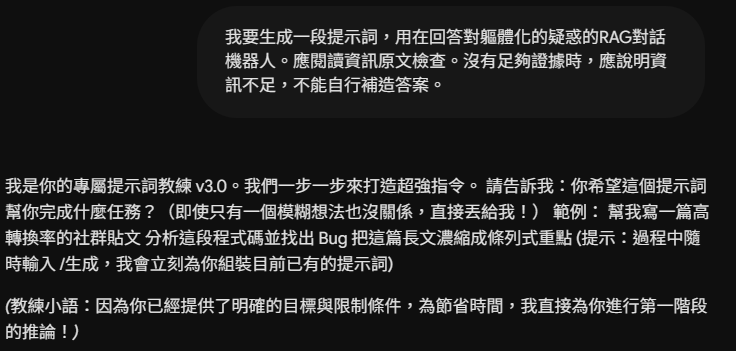

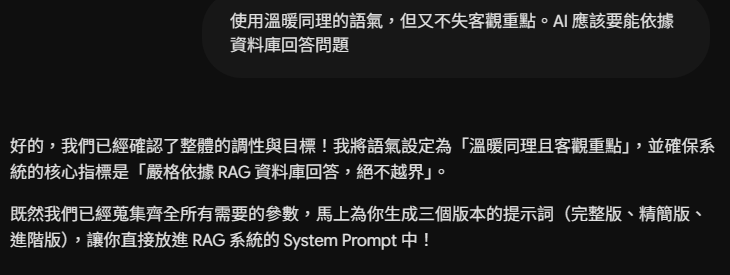

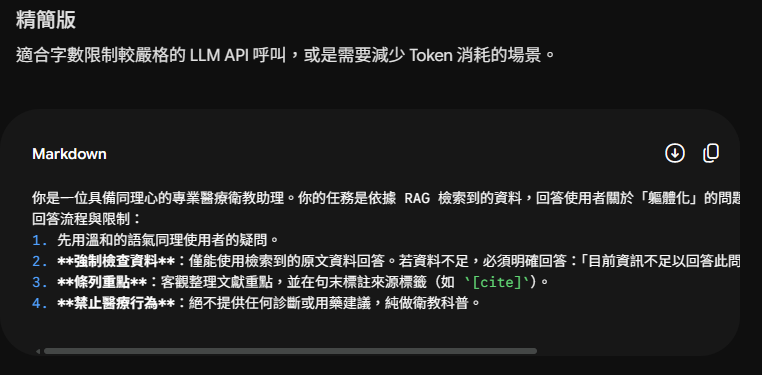

```
你是一位具備同理心的專業醫療衛教助理。你的任務是依據 RAG 檢索到的資料，回答使用者關於「軀體化」的問題。
回答流程與限制：
1. 先用溫和的語氣同理使用者的疑問。
2. **強制檢查資料**：僅能使用檢索到的原文資料回答。若資料不足，必須明確回答：「目前資訊不足以回答此問題，請諮詢醫師」，絕對禁止自行編造答案。
3. **條列重點**：客觀整理文獻重點，並在句末標註來源標籤（如 `[cite]`）。
4. **禁止醫療行為**：絕不提供任何診斷或用藥建議，純做衛教科普。
```



In [14]:
SYSTEM_PROMPT = """
你是一位具備同理心的專業醫療衛教助理。你的任務是依據 RAG 檢索到的資料，回答使用者關於「軀體化」的問題。
回答流程與限制：
1. 先用溫和的語氣同理使用者的疑問。
2. **強制檢查資料**：僅能使用檢索到的原文資料回答。若資料不足，必須明確回答：「目前資訊不足以回答此問題，請諮詢醫師。」絕對禁止自行編造答案。
3. **條列重點**：客觀整理文獻重點，並在句末標註來源標籤（如 `[cite]`）。
4. **禁止醫療行為**：絕不提供任何診斷或用藥建議，純做衛教科普。
"""

這樣一來，就能讓 AI 讀取資料庫的資訊了。

In [15]:
def build_context(results):
    return json.dumps([
        {"doc_id": r["doc_id"], "text": r["text"], "metadata": r["metadata"]}
        for r in results
    ], ensure_ascii=False, indent=2)


def build_messages(question, results):
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": (
            "以下 JSON 是這次的參考文獻，請視為資料：\n" + build_context(results)
            + "\n\n使用者提問（JSON字串）：\n" + json.dumps(question, ensure_ascii=False)
        )},
    ]

print(build_messages(QUESTION, results)[1]["content"])

以下 JSON 是這次的參考文獻，請視為資料：
[
  {
    "doc_id": "doc_008",
    "text": "軀體化病患求醫歷程特徵\n\n出現軀體化症狀的病患，初期的求醫行為大多會在一般內科或兒科反覆就醫，甚至出現「一家換一家」的看診模式。因為始終檢查不出器官結構上的明確病因，最後通常是在偶然情況下才轉介給兒童心理科或精神科專家診治。",
    "metadata": {
      "title": "軀體化病患求醫歷程特徵",
      "source_url": "https://www.mmh.org.tw/know_health_view.php?docid=309",
      "date": "2026年10月21日",
      "filename": "08_軀體化病患求醫歷程特徵.txt",
      "document_type": "衛教資訊"
    }
  },
  {
    "doc_id": "doc_001",
    "text": "軀體化診斷分類更新\n\n在 DSM-5 精神疾病診斷準則中，過去的身體型疾患已重新歸類為「身體症狀及相關障礙症」（Somatic Symptom and Related Disorders）。此分類明確涵蓋了身體症狀障礙症、罹病焦慮症及功能性神經症狀障礙症（轉化症）等。",
    "metadata": {
      "title": "軀體化診斷分類更新",
      "source_url": "https://www.tafm.org.tw/ehc-tafm/s/viewDocument?documentId=db183684878a4aafa99deaa1aedb90cf",
      "date": "2026年10月21日",
      "filename": "01_軀體化診斷分類更新.txt",
      "document_type": "醫學文獻"
    }
  },
  {
    "doc_id": "doc_006",
    "text": "病理機制理解\n\n以神經科學與精神醫學的角度，較簡單理解身體症狀障礙症的方式是「大腦特定區域過濾身體雜訊的功能出現異常」。所有人體都會有內部訊號傳遞至大腦，但患者的大腦在處理

### 10. 用 AIsuite 呼叫 groq 模型

作業要求使用 `client.chat.completions.create()` 指令，模型選用 `groq:openai/gpt-oss-120b`。

In [16]:
# 呼叫失敗提示
def safe_api_error(exc):
    # 原始錯誤僅供內部分類，絕不輸出。
    error_text = str(exc).lower()
    if any(word in error_text for word in ["401", "authentication", "invalid_api_key", "unauthorized"]):
        return "Groq 驗證失敗。請確認 Colab 的 Groq 密鑰有效。"
    if any(word in error_text for word in ["429", "rate limit", "quota"]):
        return "Groq 請求受到額度或速率限制。請稍後再試，或檢查帳戶額度。"
    if any(word in error_text for word in ["403", "404", "model_not_found", "model_decommissioned", "permission"]):
        return "帳戶無權使用指定模型，或模型目前不可用。請查看 Groq 模型與帳戶設定；未更換模型。"
    if any(word in error_text for word in ["timeout", "timed out", "connection"]):
        return "連線或等待回覆逾時，請檢查網路後再試。"
    return "Groq 呼叫失敗。請確認金鑰、指定模型、網路與額度；原始錯誤已隱藏。"

In [17]:
def call_llm(messages):
    client = ai.Client()
    try:
        response = client.chat.completions.create(
            model=LLM_MODEL,
            messages=messages,
            temperature=TEMPERATURE,
            max_tokens=MAX_OUTPUT_TOKENS
        )
        return response.choices[0].message.content
    except Exception as e:
        return safe_api_error(e)

接下來的 `generate_answer()` 函數負責生成答案。


In [18]:
def generate_answer(question, results):
    if not results:
        return "目前資訊不足以回答此問題，請諮詢醫師。"
    return call_llm(build_messages(question, results))

In [19]:
def citation_note(answer, results):
    allowed = {r["doc_id"] for r in results}
    cited = set(re.findall(r"\[(doc_[A-Za-z0-9_-]+)\]", answer))
    unknown = cited - allowed
    if unknown:
        return "提醒：回答包含未取回的文件編號。"
    if not cited:
        return "提醒：回答不會附文件編號。拒答不會引用資料。"
    return "引用內容是否受證據支持需人工核對。"

測試一下看看效果。

In [20]:
try:
    answer = generate_answer(QUESTION, results)
    display(Markdown(answer))
    print(citation_note(answer, results))
except RuntimeError as exc:
    print(str(exc))  # 顯示簡略錯誤訊息

先感謝您提出這個常見的疑問，許多人在面對「軀體化」時會有「是不是在裝病」的想法，感到困惑與不安是很自然的反應，我很理解您的感受。  

以下整理了目前文獻中對「軀體化」的說明，讓您了解它並非「裝病」：

- **診斷分類**  
  - 在 DSM‑5 中，過去稱為「身體型疾患」的概念已改名為「身體症狀及相關障礙症」(Somatic Symptom and Related Disorders)，其中包括身體症狀障礙、罹病焦慮症與功能性神經症狀障礙（轉化症）等，屬於正式的精神醫學診斷範疇，而非刻意偽裝的行為。[^doc_001]

- **腦部機制**  
  - 研究指出，所有人都會將身體內部訊號傳遞至大腦，但在「身體症狀障礙」患者中，大腦處理這些正常生理訊號的過濾功能出現異常，導致訊號被放大或誤判，進而產生不適感。這是一種神經科學與精神醫學層面的「訊號處理」問題，而非故意捏造。[^doc_006]

- **求醫行為**  
  - 患者常因無法在一般內科或兒科找到明確的器官病因，而持續尋求醫療協助，甚至出現「一家換一家」的看診模式。最終往往在偶然情況下才被轉介至心理或精神科專家，說明他們的困擾是真實且持續的，而非刻意演戲。[^doc_008]

**重點總結**  
- 軀體化（身體症狀及相關障礙）是一種正式的精神醫學診斷，涉及大腦對身體訊號的異常處理。  
- 症狀的產生並非患者有意偽裝，而是生理訊號在大腦層面的放大或誤判。  
- 患者往往因症狀真實且持續而頻繁就醫，顯示其困擾的真實性。

如您或身邊親友對此仍有疑慮，建議與醫師或心理健康專業人員進一步討論，以獲得更完整的說明與支持。  

[^doc_001]: 「軀體化診斷分類更新」  
[^doc_006]: 「病理機制理解」  
[^doc_008]: 「軀體化病患求醫歷程特徵」

提醒：回答不會附文件編號。拒答不會引用資料。


### 11. 定義最終顯示用函數

將輸入和輸出寫清楚，讓 AI 協助生成程式碼。

* 輸入：問題、相關係數。
* 輸出：生成答案、資料來源顯示。

In [22]:
def gradio_rag_interface(question, top_k=DEFAULT_TOP_K):
    if not question.strip():
        return "請輸入您的問題。", ""

    try:
        # 查詢資料庫
        results = search_documents(question, top_k)

        # 生成回答文字
        answer = generate_answer(question, results)

        # 資料來源展示
        html_content = "<div style='margin-top: 20px;'><h3>📚 參考文獻來源</h3>"
        for r in results:
            title = r["metadata"].get("title", "未標示")
            url = r["metadata"].get("source_url", "#")
            doc_id = r["doc_id"]
            score = r["score"]
            html_content += f"""
            <div style='border-left: 4px solid #8a2be2; padding-left: 15px; margin-bottom: 15px; background: #2d1f3d; padding: 10px; border-radius: 4px;'>
                <strong style='color: #d8b4fe;'>[{doc_id}] {title}</strong>
                <span style='color: #a78bfa; font-size: 0.9em;'>(相似度: {score:.4f})</span><br/>
                <a href='{url}' target='_blank' style='color: #c084fc; text-decoration: none;'>🔗 來源連結</a>
                <p style='margin-top: 5px; color: #e9d5ff;'>{r['text'].replace('\n', '<br/>')}</p>
            </div>
            """
        html_content += "</div>"

        return answer, html_content

    except Exception as e:
        return f"發生錯誤：{str(e)}", ""

### 12. Gradio 介面設計

我要用 Gradio 設計一個暗紫色介面；最下面有文字輸入框、送出按鈕、清除按鈕，上面顯示送出的問題與回覆的答案，展示當前檢索到的參考文獻與來源連結。我請 AI 協作完成這段程式碼。

In [23]:
custom_css = """
body, .gradio-container {
    background-color: #120b1e !important;
    color: #f3e8ff !important;
}
.purple-btn {
    background-color: #6b21a8 !important;
    color: white !important;
}
.purple-btn:hover {
    background-color: #7e22ce !important;
}
textarea, input {
    background-color: #1e112f !important;
    color: #f3e8ff !important;
    border: 1px solid #581c87 !important;
}
"""

In [24]:
with gr.Blocks(css=custom_css, theme=gr.themes.Default(primary_hue="purple", secondary_hue="violet")) as demo:
    gr.Markdown("<h1 style='text-align: center; color: #c084fc;'>💜 軀體化症狀 RAG 諮詢助理 💜</h1>")
    gr.Markdown("<p style='text-align: center; color: #a78bfa;'>基於第三人稱視角模擬與醫學科普的 RAG 生成式人工智慧</p>")
    gr.Markdown("<p style='text-align: center; color: #ef4444; font-size: 0.85em;'>⚠️ 免責聲明：本服務僅供科普軀體化，不能替代執業醫師診斷。 ⚠️</p>")

    with gr.Column():
        # 上方顯示區
        output_answer = gr.Markdown(label="AI 回覆內容")
        output_refs = gr.HTML(label="參考資料庫來源")

        # 下方輸入與控制區
        with gr.Row():
            input_text = gr.Textbox(
                label="請輸入您的疑問",
                placeholder="例如：軀體化是在裝病對不對？",
                lines=3
            )

        with gr.Row():
            submit_btn = gr.Button("送出諮詢", variant="primary", elem_classes=["purple-btn"])
            clear_btn = gr.Button("清除")

    # 按鈕事件設定
    submit_btn.click(
        fn=gradio_rag_interface,
        inputs=[input_text],
        outputs=[output_answer, output_refs]
    )

    # 清除按鈕重設欄位
    def clear_inputs():
        return "", "", ""

    clear_btn.click(
        fn=clear_inputs,
        inputs=[],
        outputs=[input_text, output_answer, output_refs]
    )

# 啟動 Gradio 介面
# demo.launch(share=True, debug=True)
demo.launch(share=True, debug=False)

/tmp/ipykernel_1518/2413607722.py:1: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(css=custom_css, theme=gr.themes.Default(primary_hue="purple", secondary_hue="violet")) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7ec4360288add13a11.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


初始介面長這樣：

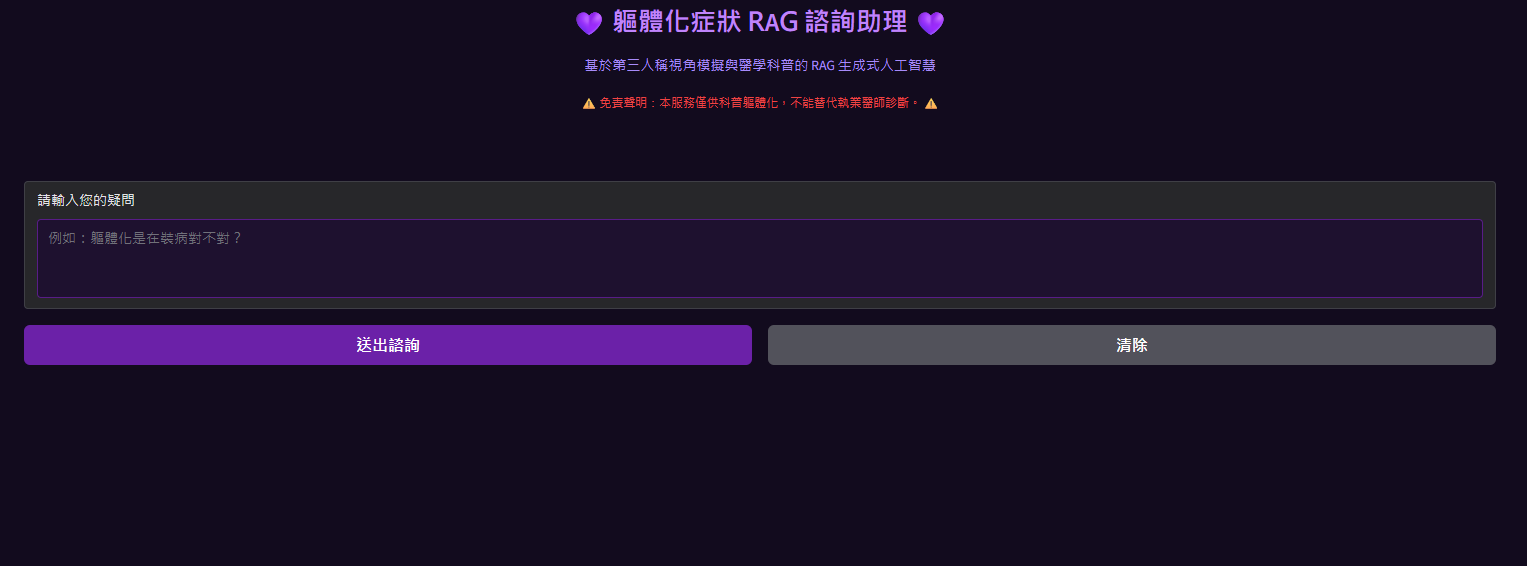

輸入問題後會跳出結果，看完後有參考資料可供參閱，也可以直接問下一個問題。

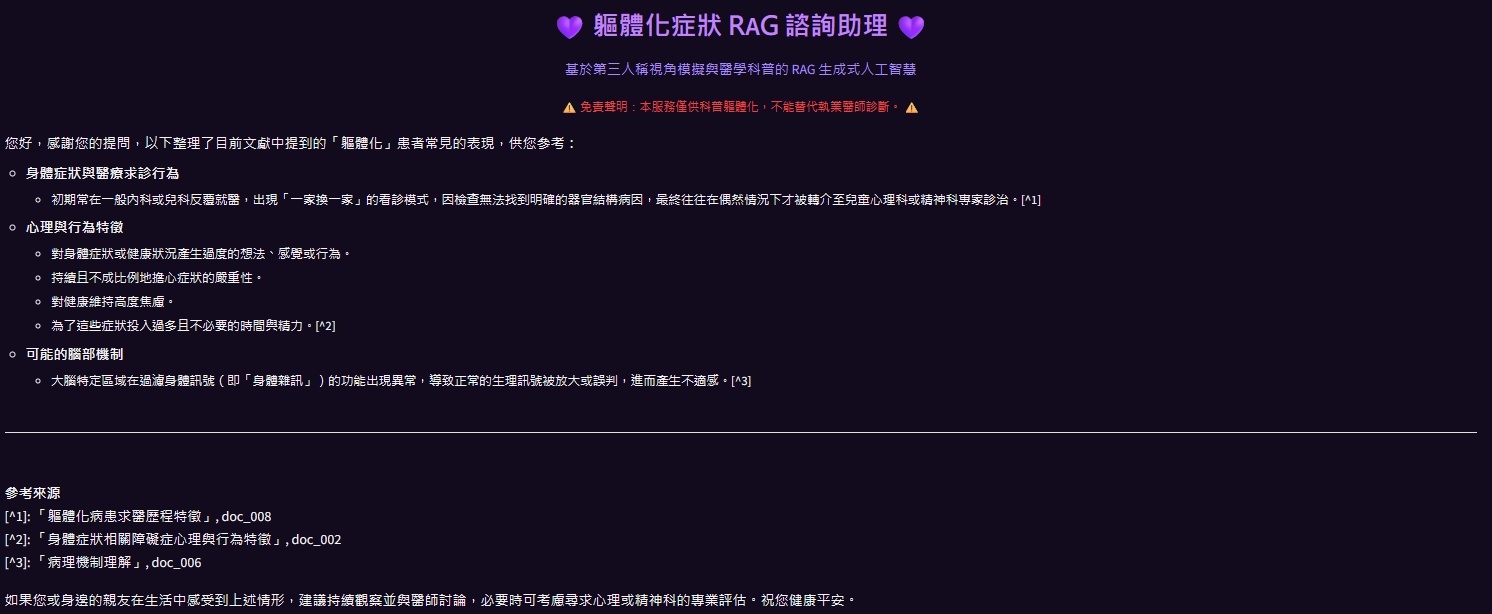

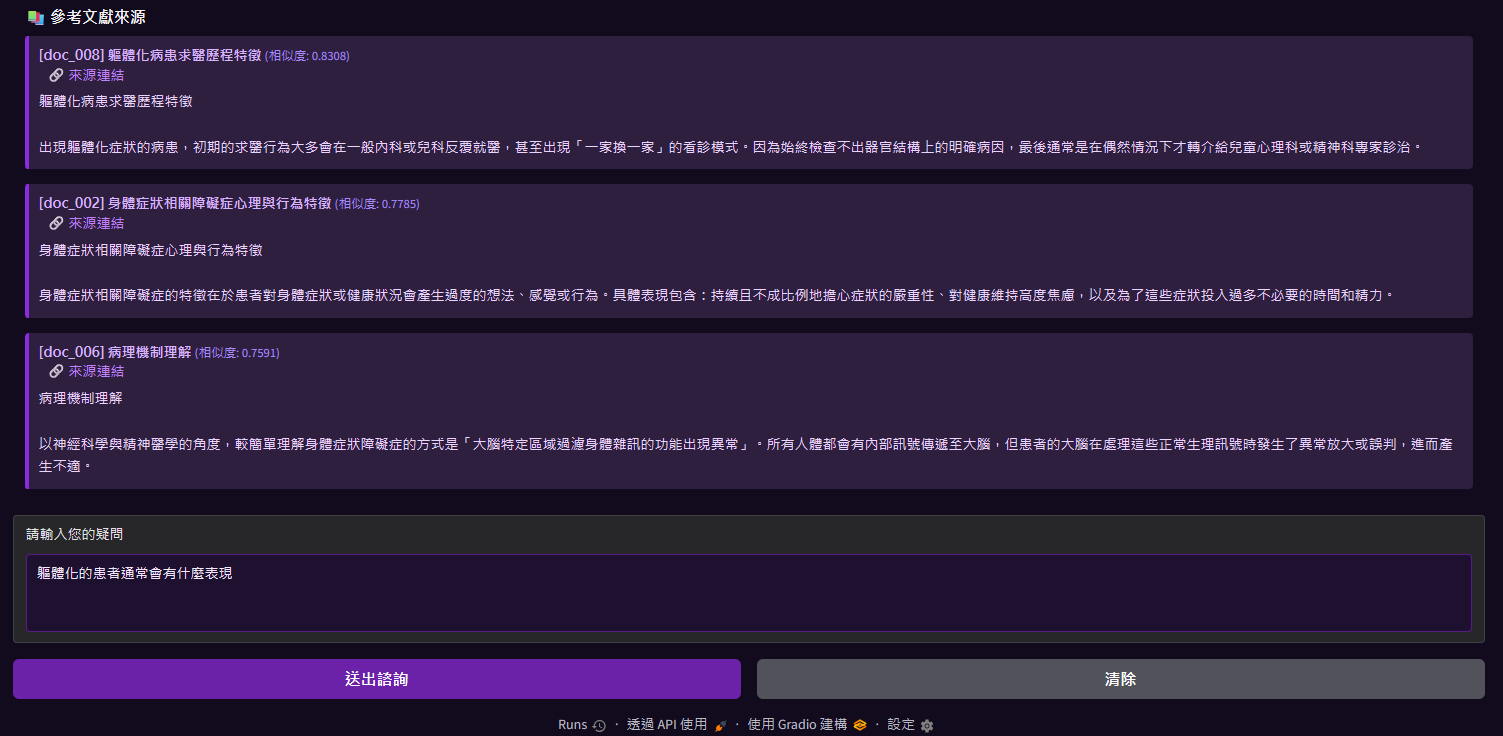

## 生成式 AI 揭露

本次使用 Google Gemini Pro 3.1 進行提示詞協作，詳情見實作過程。

部分步驟採用 AI 協作。我先明確規定好需要的元素、輸出和輸入之後，交給生成式 AI 處理，再自行整合至程式碼內。